## inference of non-drift-like trajectories 
via  forward-time drift-only simulations and permutation based statistics

## 0. General

### 0.1. Load libraries

In [1]:
import os, pandas as pd, statistics as st, random
import numpy as np, bisect
from Bio import SeqIO
from scipy.optimize import minimize
from scipy.stats import binom
from scipy.special import betainc

In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
import matplotlib.cm as cm

import seaborn as sns

sns.set_theme(style="white", font="Arial")
sns.set_context({'font.size': 10.0, 'axes.labelsize': 12, 'axes.titlesize': 14,
                 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
                 'legend.title_fontsize': None, 'axes.linewidth': 0.8, 'grid.linewidth': 0.8,
                 'lines.linewidth': 1.5, 'lines.markersize': 6.0, 'patch.linewidth': 1.0,
                 'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.minor.width': 0.3,
                 'ytick.minor.width': 0.3, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
                 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,})

plt.rcParams['xtick.bottom'] = True
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 12
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True


### 0.2. General variables 

In [3]:
detection_limit = 0.01 #1%

In [4]:
donors = [1,2,3,4]
replicates = ["A", "B", "C"]
passages = list(range(0, 110, 10))
tech_reps = [1,2 ]
populations = ["1A", "1B", "1C", "2A", "2B", "2C", "3A", "3B", "3C", "4A", "4B", "4C"]
segments = ["1-PB2", "2-PB1", "3-PA", "4-HA", "5-NP", "6-NA", "7-M", "8-NS"]

hours_per_passage = 72 #hours
generation_time = 6 #hours > assumption based on Baccam, et al. 2006

In [5]:
segment_nuc_cds = {r.id:r.seq for r in SeqIO.parse('../data/references/stock_consensus_cds.fasta', 'fasta')}


In [6]:
#color palette 
population_cpal = [ "#005fb9", "#58b4e2", "#8ee6ff", "#860041", "#ca0090", "#ff53c0", "#006e00", "#77a908", "#bbe837", "#0000ba", "#5f38ed", "#d49eff" ]
segment_cpal = ["#ea5545","#f46a9b", "#ef9b20", "#ede15b", "#87bc45", "#27aeef", "#776efa", "#b33dc6"]



### 0.3. Functions

#### Maximum likelihood estimation of binomial proportions of SNV frequencies 


**binomial distribution**: $P_{x} = \binom{n}{x} \cdot p^x \cdot (1-p)^{n-x}$
- $P$: binomial probability 
- $x$: number of times for a specific outcome within n trails
- $\binom{n}{x}$: number of combinations
- $p$: probability of success on a single trail
- $(1-p)^{n-x}$: probability of failure on a single trail
- $n$: number of trails

**likelihood fuction**: $ L(p; n, y) =  \binom{n}{y} p^y \cdot (1-p)^{n-y}$

log likelihood is easier to solve, so:  
**log likelihood fuction**: $ln(L) = ln(L(p; n, y)) = ln(\binom{n}{y}) + y \cdot ln(p) + (n - y) \cdot ln(1-p)$


In [7]:
def neg_log_likelihood(p, observations, trials):
        total_log_likelihood = 0
        for i, x in enumerate(observations):
            n = trials[i]
            total_log_likelihood += binom.logpmf(x, n, p)
        return -total_log_likelihood

def estimate_binomial_mean(count, depth):
    # calculate maximum likelihood estimate using Nelder-Mead for noisy measurements
    x0 = st.mean([count[i]/x for i, x in enumerate(depth)]) #initial guess 
    result = minimize(neg_log_likelihood, x0=x0, args=(count, depth), bounds=[(0, 1)], method="Nelder-Mead")
    if not result.success:
        raise Exception(f'optimizer was not successfull')
    p_mle = result.x[0]
    return p_mle


In [8]:
def load_simulation_results(simulation_file, lim=None):
    simulations = pd.read_csv(simulation_file)
    #only working with the first 100 simulation here for now
    if lim is not None:
        simulations = simulations[simulations["simulation"]<lim]
    simulations = simulations.melt(id_vars=["simulation", "passage", "replicate", "depth"], var_name="position", value_name="count")

    for c in simulations.columns:
        simulations[c] = simulations[c].astype(int)

    simulations = simulations.reset_index(drop=True)
    simulations['frequency'] = simulations['count'] /simulations['depth']

    simulations = simulations.pivot(index=["simulation", "position", "passage"],columns="replicate",
                    values=["depth", "count", "frequency"])
    simulations.columns = [f"{c[0]} {c[1]}" for c in simulations.columns]

    #remove observation where both freq 1 and freq 2 are below the detection limit
    #'true frequency' will then be under the detection limit anyway so there is no point of estimating the true frequency
    simulations = simulations[(simulations["frequency 1"]>=detection_limit)|(simulations["frequency 2"]>=detection_limit)]

    #using maximum likelihood estimation of the binomial proportions estimate the nucleotide, codon, and amino acid frequency
    for i, row in simulations.iterrows():
        counts = row[[c for c in simulations.columns if "count" in c]]
        depths = row[[c for c in simulations.columns if "depth" in c]]
        simulations.loc[i, "frequency"] = estimate_binomial_mean([int(nc) for nc in counts], [int(nd) for nd in depths])

    #drop techical replicate columns  > save space
    simulations = simulations.drop(columns=[c for c in simulations.columns if c !="frequency"])

        
    #remove all observations that have an estimated true frequecy below the detection limit 
    simulations = simulations[simulations["frequency"]>=detection_limit]

    #pivot to frequencies 
    simulations = simulations.reset_index().pivot(index=["simulation", "position"], columns=["passage"]).fillna(0)
    simulations.columns = simulations.columns.droplevel(0)
    return simulations

In [9]:
def load_simulation_depths_allele_counts(simulation_file, passages, lim=None,):
    simulations = pd.read_csv(simulation_file)
    #only working with the first 100 simulation here for now
    if lim is not None:
        simulations = simulations[simulations["simulation"]<lim]
    simulations = simulations.melt(id_vars=["simulation", "passage", "replicate", "depth"], var_name="position", value_name="count")
    simulations["position"] = simulations["position"].astype(int)
    
    
    D = simulations.reset_index().pivot(index=["simulation", "position", "replicate"], columns=["passage"], values="depth").fillna(0)
    
    #dont care about zero counts
    simulations = simulations[simulations["count"]>0]
    
    A = simulations.reset_index().pivot(index=["simulation", "position", "replicate"], columns=["passage"], values="count").fillna(0)

    for i, passage in enumerate(passages):
        if passage not in D.columns:#this should only apply to passage 0 
            D[passage] = D[passages[i+1]] #just using depth of next passage assuming this is reflective of population > given that this is a simulation....
        if passage not in A.columns:
            A[passage] = 0 #not observed allele

    A = A[passages]
    D = D[passages]
    
    idx = A.index.to_numpy()
    A = A.to_numpy()
    D = D.to_numpy()

    return D, A, idx

#### Hidden Markov Model

**Input**  
Depth matrix $\mathbf{D}_{M,T}$ where $N$ is the number of alleles and $T$ is the total number of timepoints.  
Allele count matrix $\mathbf{A}_{M,T}$ where $N$ is the number of alleles and $T$ is the total number of timepoints.  
- $M$ = mutations 
- $T$ = timepoints in seasons

For depth and allele count matrices not including unknown AA's or gaps (X)


**States**
- Ancestral: Allele is ancestral state no detectable SNVs have observed.
- Polymorphic: There are one or multiple SNVs are the allele
- Fixed: An SNV has fixed at this allele

In [10]:
def HMM(D, A, a=0.33, ap=0.33, af=0.33,pa=0.33, p=0.33, pf=0.33, fa=0.33, fp=0.33, f=0.33,
        n_iter=100, min_error=1e-3, epsE=0.025, epsF=0.02, p0v= 0.01, p1v=0.01):
        # br=1e-10, er=0.25, dr=1e-5, gr=0.55, fr=0.25, rr=0.3,

    #define states 
    states = {"A":0, "P":1, "F":2}
    L = len(states)

    #get information from A and D 
    M, T = A.shape #get number of mutation (M) and timepoints (T)
    R = D - A # array of alt allele  > tecnically reference

    #intialize p0 and p1 > error probability vectors 
    p0=np.full_like(D, p0v) #probability of observing error in the ancestral state
    p1=np.full_like(D, p1v) #probability of observing error in the fixed state
    Pstate = np.zeros((M,T,L)) # decoding probabilities for each state

    #initiate transition matrix
    Q = np.zeros((T,L,L))
    for t in range(T):
        Q[t,states["A"],:] = np.array([a, pa, fa]) #transtion to ancestral state 
        Q[t,states["P"],:] = np.array([ap, p, fp]) #transtion to polymorphic state 
        Q[t,states["F"],:] = np.array([af, pf, f]) #transtion to fixed state

    #Baum-Welch // Forward-Backward algorithm
    for i in range(n_iter):
        logV = np.zeros((M,T,L)) #observation likelihood // emission probabilities
        
        ancestral_beta = np.clip(betainc(A+1,R+1,2*p0),1e-300,1) #+1 for safety > does not change results
        logV[:,:,states['A']] = (D>0.5)*(np.log(ancestral_beta)-np.log(2*p0)) 

        fixed_beta = np.clip(betainc(R+1,A+1,2*p1),1e-300,1)
        logV[:,:,states['F']] = (D>0.5)*(np.log(fixed_beta)-np.log(2*p1))

        logV[:,:,states['P']] = (D>0.5)*(0.0) #polymorphic

        #normalize observation likelihood across all states
        logVmax = logV.max(axis=2)
        for l in range(L):
            logV[:,:,l]-=logVmax
        V = np.exp(logV)

        ## initialize F and B
        F = np.zeros((M,T,L)) # forward probability table
        B = np.zeros((M,T,L)) # backward probability table
        
        # All mutations start in ancestral state at timepoint = 0
        F[:,0,states['A']] = 1.
        
        # mutations can end up in any state
        B[:,T-1,states['A']] = 1.0/(L-1)
        B[:,T-1,states['P']] = 1.0/(L-1)
        B[:,T-1,states['F']] = 1.0/(L-1)

        #actual Baum-Welch // Forward-Backward algorithm
        for t in range(1,T): #forward
            F[:,t,:] = V[:,t,:]*(np.dot(F[:,t-1,:], np.transpose(Q[t-1,:,:])))
            sum_F = F[:,t,:].sum(axis=1) + (F[:,t,:].sum(axis=1) < 1e-12)
            F[:,t,:] /= np.outer(sum_F, np.ones(L))

        for t in reversed(range(T-1)): #backward
            B[:,t,:] =  np.dot(B[:,t+1,:]*V[:,t+1,:], Q[t,:,:])
            sum_B = B[:,t,:].sum(axis=1) + (B[:,t,:].sum(axis=1) < 1e-12)
            B[:,t,:] /= np.outer(sum_B, np.ones(L))
         
        #compute posterior states    
        FB = F * B
        denom = FB.sum(axis=2, keepdims=True)
        denom = np.where(denom < 1e-300, 1.0, denom)
        Pstate = FB / denom     

        # Update the error probability vectors
        aen = (A * Pstate[:, :, states["A"]]).sum(axis=1)  # ancestral error numerators
        aed = (D * Pstate[:, :, states["A"]]).sum(axis=1)  # ancestral error denominators
        den = (R * Pstate[:, :, states["F"]]).sum(axis=1)  # derived error numerators
        ded = (D * Pstate[:, :, states["F"]]).sum(axis=1)  # derived error denominators

        # Add a small positive value to the denominators to avoid division by zero
        aed += 1e-12
        ded += 1e-12

        # Use parentheses to fix the boolean condition
        p0 = np.outer(np.clip(aen / (aed + (aed < 1e-12)), min_error, epsE), np.ones(T))
        p1 = np.outer(np.clip(den / (ded + (ded < 1e-12)), min_error, epsF), np.ones(T))

    #Viterbi algorithm // infer most likely sequence of states
    mlt = np.zeros((M,T,L)) #max likelihood table
    spt = np.zeros((M,T,L)) #state pointer table

    mlt[:,0,:] = F[:,0,:] #all mutations state in ancestral state at timepoint = 0
    for t in range(1,T):
        nl = mlt[:,t-1,None,:]*Q[None,t-1,:,:] #new likelihoods
        mlt[:,t,:] = nl.max(axis=2)
        spt[:,t-1,:] = nl.argmax(axis=2)

        mlt[:,t,:] *= V[:,t,:]

        scale = np.outer(np.clip(mlt[:,t,:].max(axis=1),1e-300,1e300), np.ones(L))
        mlt[:,t,:] /=scale

    #follow path back
    Ls = np.zeros((M,T), dtype=np.int32)
    Ls[:,-1] = mlt[:,-1,:].argmax(axis=1)
    for t in reversed(range(1,T)):
        for m in range(M):
            Ls[m,t-1] = spt[m,t-1,Ls[m,t]]

    S = pd.DataFrame(Ls).replace({v:s for s,v in states.items()}).to_numpy()   
    return Pstate, Ls,S, p0, p1


In [11]:
def determine_observations(states,timepoints):
    '''determine when a mutation was observed based on the states'''
    observed_states,observation_timepoints = [], []
    observed_state, observation_period = [], []
    for i, state in enumerate(states):
        if state != "A":
            observed_state.append(state)
            observation_period.append(timepoints[i])
        else:
            if len(observed_state) > 0:
                observed_states.append(observed_state)
                observation_timepoints.append(observation_period)
                observed_state, observation_period = [], []
    if len(observed_state) > 0:
        observed_states.append(observed_state)
        observation_timepoints.append(observation_period)
    return observed_states, observation_timepoints

In [12]:
def clip_pvalue(pvalue, pvalue_threshold=(0.05)**(1/2)):
    return 1 if pvalue > pvalue_threshold else pvalue

def calculate_composite_statistic(pvalue_list):
    composite_statistic = clip_pvalue(pvalue_list[0])
    for pvalue in pvalue_list[1:]:
        composite_statistic *= clip_pvalue(pvalue)#*np.log10(1/pvalue)
    return composite_statistic

def calculate_pvalue_from_list(stat_list, query_stat, diff="greater"):
    stat_list = sorted(stat_list)
    if diff == "greater":
        n_diff = len(stat_list) - bisect.bisect_left(stat_list, query_stat)
    elif diff == "smaller":
        n_diff = len(stat_list) - bisect.bisect_left(stat_list, query_stat)
    else:
        print ("difference can be greater or smaller. Operation for supplied difference is not known")
        return
        
    return (n_diff+1)/(len(stat_list)+1)


## 1. Drift-only forward-time simulations

### 1.1. Run simulations 

simulation parameters used
- mutation rate: 3e-6
- apical wash release fraction: 0.5
- wash recovery fraction: 0.5
- genome length: 1701 (CDS length of HA)
- n simulations: 100
- successful infection fraction: 0.9
- n input virions: 1000

In [13]:
sim_dir = "../results/simulations"
if not os.path.isdir(sim_dir):
    os.makedirs(sim_dir)
    

raw_sim_dir = os.path.join(sim_dir, "raw_output")
if not os.path.isdir(raw_sim_dir):
    os.makedirs(raw_sim_dir)
    
bash_file = "../scripts/bash/simulation_commands.sh"

In [14]:
threads = 1 #adjust to CPU of machine

param_dict = {"--n-sims": 100,
              "--passages": 100,
              "--input-virions":1000,
              "--successful-infection-frac": 0.9,
              "--wash-recovery-frac":0.5,
              "--apical-release-fraction":0.5,
              "-mu":0.000003, #3e-6
              "--within-host-basic-reproduction-number":5
              }

cds_lengths = {k:len(v) for k, v  in segment_nuc_cds.items()}

repo_dir = "~/LTEE-flu" #CHANGE PATH TO ACTUALLY LOCATION OF THE REPO
with open(bash_file, "w") as fw: 
    fw.write("#!/bin/bash\n\n")
    fw.write(f"cd {repo_dir}\n")
    
    for segment, gl in cds_lengths.items():
        file_name = f"simulation_{segment}_L{gl}.csv"
        simulation_file = os.path.join(raw_sim_dir, file_name)
        
        
        cmd = ["python", "./scripts/simulations.py", '-t', str(threads), '-o', simulation_file.replace("../../", "../"), "--genome-length", str(gl), '-v']
        for p, v in param_dict.items():
            cmd.extend([p, str(v)])
        fw.write(" ".join(cmd))


##### Need to have run the bash file generated above 
or well unprocessed simulations in raw simulation directory needs to have files

### 1.2. Process simulation output and load results

In [15]:
processed_sim_dir = os.path.join(sim_dir, "processed_output")
if not os.path.isdir(processed_sim_dir):
    os.makedirs(processed_sim_dir)
    

In [16]:
#process simulations 
simulations = []  
for segment, gl in cds_lengths.items():
    file_name = f"simulation_{segment}_L{gl}.csv"
    simulation_file = os.path.join(raw_sim_dir, file_name)
    processed_sim_file = os.path.join(processed_sim_dir, file_name)
    
    if not os.path.isfile(processed_sim_file):
        sims = load_simulation_results(simulation_file)
        sims.columns.name = None
        for passage in passages:
            if passage not in sims.columns:
                sims[passage] = 0.0
        sims = sims[passages]
        sims.reset_index().to_csv(processed_sim_file, index=False)
    else:
        sims = pd.read_csv(processed_sim_file)
        sims["refname"] = segment
        sims = sims.set_index(["refname", "simulation", "position"]).sort_index()
        sims = sims.rename(columns={c:int(c) for c in sims.columns})
        try:
            simulations = pd.concat([simulations, sims])
        except:
            simulations = sims
    

## 2. Simulation vs observations visualized

In [17]:
#load data
#load snv summary 
snv_summary = pd.read_csv("../results/snv_summary.csv", keep_default_na=False, na_values=[""]).set_index(["population", "refname", "nucpos", "snv"]).sort_index()

#create overview of non-synonymous SNVs (for convienence)
non_synonymous_dict = {segment:[] for segment in segments}
for i in snv_summary[snv_summary["non_synonymous"]==True].index.droplevel(0):
    non_synonymous_dict[i[0]].append(i[-1])
    

#load trajectories 
trajectories = pd.read_csv("../results/snv_trajectories.csv").set_index(["population", "refname", "nucpos", "snv"]).sort_index()
trajectories = trajectories.rename(columns={c:int(c) for c in trajectories.columns})

                     
plot_trajec = trajectories.reset_index().set_index(["refname", "population", "nucpos", "snv"]).sort_index()

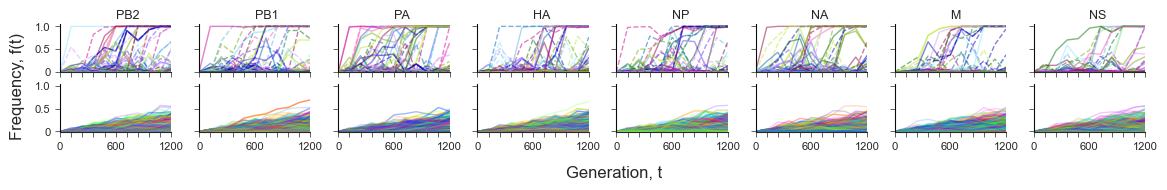

In [18]:
fig = plt.figure(figsize=(14, 1.4))
gs = gridspec.GridSpec(2, len(segments), wspace=0.25, hspace=0.23)

random.seed(10)
n_sims_toplot = 100
color_list = [mcolors.to_hex(cm.gist_rainbow(i /( n_sims_toplot-1))) for i in range(n_sims_toplot)]
random_sims_toplot = random.sample(simulations.index.get_level_values(1).unique().tolist(), n_sims_toplot)
unique_trajectories_only=True

for i, refname in enumerate(segments):
    df = plot_trajec.loc[refname]
    ltee_ax = fig.add_subplot(gs[0,i])
    sim_ax = fig.add_subplot(gs[1,i])

    df = plot_trajec.loc[refname]
    idx_list =df.index.tolist()
    random.shuffle(idx_list)
    
    for (population, nucpos, snv) in idx_list:
        freqs = [f for f in df.loc[(population, nucpos, snv)] if not pd.isna(f)]
        timepoints = passages
        donor, replicate = population
        
        ltee_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=0.5, ls='-' if snv in non_synonymous_dict[refname] else '--')
        
    if unique_trajectories_only:
        sims = simulations.loc[refname].drop_duplicates()
        indices = sims.index.tolist()
        random.shuffle(indices)  
    for (sim,p) in indices:
        if sim not in random_sims_toplot:
            continue
        freqs = sims.loc[(sim, p)].values
        sim_ax.plot(passages, freqs, lw=1, alpha=0.2, color=color_list[random_sims_toplot.index(sim)])
    
        
    for ax in [ltee_ax, sim_ax]:
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
        if i !=0:
            ax.set_yticklabels([])
        else:
            ax.set_yticklabels([0, 0.5, 1.0], size=8)
    ltee_ax.set_xticklabels([])
    sim_ax.set_xticklabels([0, "", "", "", "", int((50*hours_per_passage)/generation_time), 
                            "", "", "", "", int((100*hours_per_passage)/generation_time)], size=8)
    
    if i == 0:
        sim_ax.text(-45, 1, "Frequency, f(t)", rotation=90, va="center")
    if i == 3:
        sim_ax.text(80, -1, "Generation, t", ha="left")
        
    ltee_ax.text(50, 1.1, refname.split("-")[-1], va="bottom", size=9)
          

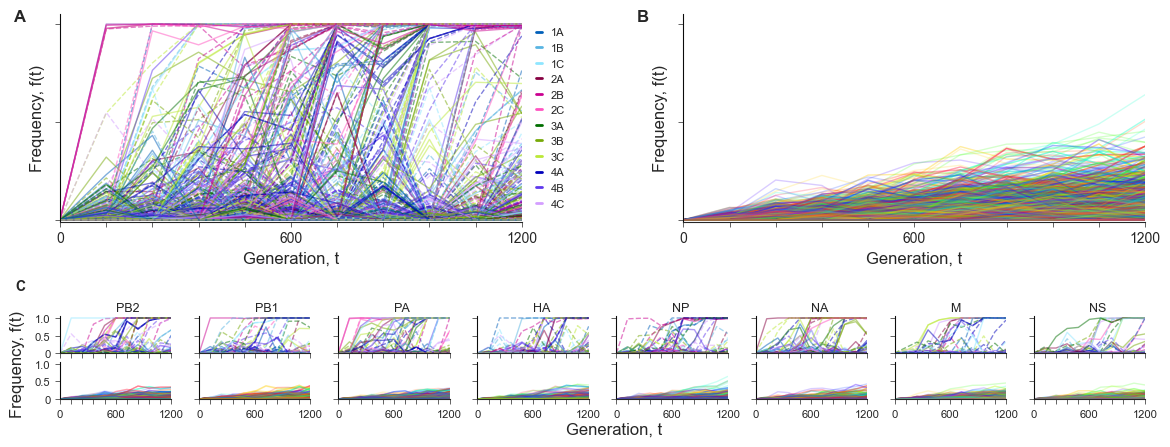

In [19]:
fig = plt.figure(figsize=(14, 5))
gs = gridspec.GridSpec(2, 1, wspace=0.05, hspace=0.65, height_ratios=[2.5,1])

gsi = gridspec.GridSpecFromSubplotSpec(1,2, wspace=0.35, hspace=0.23, subplot_spec=gs[0])
random.seed(9)

#ltee observed trajectories
ltee_ax = fig.add_subplot(gsi[0])
idx_list =plot_trajec.index.tolist()
random.shuffle(idx_list)
for (refname, population, nucpos, snv) in idx_list:
    freqs = [f for f in plot_trajec.loc[(refname, population, nucpos, snv)] if not pd.isna(f)]
    timepoints = passages
    donor, replicate = population
    ltee_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=0.5, ls='-' if snv in non_synonymous_dict[refname] else '--')
    
population_legend_elements = []#[Line2D([0], [0], color='white', label="population", linewidth=0,)]
for i, population in enumerate(populations):
    population_legend_elements.append(Line2D([0], [0], color=population_cpal[i], label=population, linewidth=2,  ))
leg = ltee_ax.legend(handles=population_legend_elements, loc='center left', 
                        bbox_to_anchor=(1.01, 0.5,), ncols =1, fontsize=8, handlelength=0.5, edgecolor=None, frameon=False, 
                        columnspacing=0.5)
plt.setp(leg.get_title(),fontsize=9)
     
#simulated trajectories
n_sims_toplot = 12
color_list = [mcolors.to_hex(cm.gist_rainbow(i /( n_sims_toplot-1))) for i in range(n_sims_toplot)]
random_sims_toplot = random.sample(simulations.index.get_level_values(1).unique().tolist(), n_sims_toplot)
unique_trajectories_only=True

sim_ax = fig.add_subplot(gsi[1])
if unique_trajectories_only:
    sims = simulations.drop_duplicates()
    indices = sims.index.tolist()
    random.shuffle(indices)  
for (ref, sim,p) in indices:
    if sim not in random_sims_toplot:
        continue
    freqs = sims.loc[(ref, sim, p)].values
    sim_ax.plot(passages, freqs, lw=1, alpha=0.2, color=color_list[random_sims_toplot.index(sim)])

for ax in [ltee_ax, sim_ax]:
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, timepoints[-1])
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
    if i !=0:
        ax.set_yticklabels([])
    else:
        ax.set_yticklabels([0, 0.5, 1.0], size=8)
    ax.set_xticklabels([0, "", "", "", "", int((50*hours_per_passage)/generation_time), 
                            "", "", "", "", int((100*hours_per_passage)/generation_time)], size=10)
    ax.set_xlabel("Generation, t")
    ax.set_ylabel("Frequency, f(t)")
ltee_ax.text(-10, 1, "A", va="bottom", fontweight="bold")
sim_ax.text(-10, 1, "B", va="bottom", fontweight="bold")

gsi = gridspec.GridSpecFromSubplotSpec(2, len(segments), wspace=0.25, hspace=0.23, subplot_spec=gs[-1])

for i, refname in enumerate(segments):
    df = plot_trajec.loc[refname]
    ltee_ax = fig.add_subplot(gsi[0,i])
    sim_ax = fig.add_subplot(gsi[1,i])

    df = plot_trajec.loc[refname]
    idx_list =df.index.tolist()
    random.shuffle(idx_list)
    
    for (population, nucpos, snv) in idx_list:
        freqs = [f for f in df.loc[(population, nucpos, snv)] if not pd.isna(f)]
        timepoints = passages
        donor, replicate = population
        
        ltee_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=0.5, ls='-' if snv in non_synonymous_dict[refname] else '--')
        
    if unique_trajectories_only:
        sims = simulations.loc[refname].drop_duplicates()
        indices = sims.index.tolist()
        random.shuffle(indices)  
    for (sim,p) in indices:
        if sim not in random_sims_toplot:
            continue
        freqs = sims.loc[(sim, p)].values
        sim_ax.plot(passages, freqs, lw=1, alpha=0.2, color=color_list[random_sims_toplot.index(sim)])
    
        
    for ax in [ltee_ax, sim_ax]:
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
        if i !=0:
            ax.set_yticklabels([])
        else:
            ax.set_yticklabels([0, 0.5, 1.0], size=8)
    ltee_ax.set_xticklabels([])
    sim_ax.set_xticklabels([0, "", "", "", "", int((50*hours_per_passage)/generation_time), 
                            "", "", "", "", int((100*hours_per_passage)/generation_time)], size=8)
    
    if i == 0:
        sim_ax.text(-45, 1, "Frequency, f(t)", rotation=90, va="center")
        ltee_ax.text(-40, 1.7, "C", va="bottom", fontweight="bold", size=10)
        
    if i == 3:
        sim_ax.text(80, -1, "Generation, t", ha="left")
        
    ltee_ax.text(50, 1.1, refname.split("-")[-1], va="bottom", size=9)
    

## 3. Indentification of non-drift like trajecotires
Simulation are treated as null model observation

Assessing if the LTEE SNV observation deviates the null model observation based on two criterea (see [calculation on appearance and transit times](./SNV_frequencies_HMM_state_assigment.ipynb)):
- Max frequency $f(t^{*}_{mk})$
- Time to fixation / max frequency $\Delta T_{mk}$

However, given that fixation does not happen in the drift simulations, fixation itself is evidence of non-drift


Computing individual P values that will be combined in a single composite statistic to combine the ev

### 3.1. Determine observations for simulated trajectories

initial transimission probabilities were estimated from our emperical SNV observations

In [20]:
#HMM initial transition probabilities 
ap=0.12
af=2.7e-3
a = 1-ap-af
pa=0.67
pf=5.6e-2
p = 1-pa-pf
fp=3e-2
fa=6.1e-3
f = 1-fp-fa



In [21]:
sim_observations = []
for segment, gl in cds_lengths.items():
    file_name = f"simulation_{segment}_L{gl}.csv"
    states_file_name = f"simulation_{segment}_L{gl}_HMM_states.csv"
    
    if not os.path.isfile(os.path.join(processed_sim_dir, states_file_name)):
        simulation_file = os.path.join(sim_dir, file_name)
        
        sim_D, sim_A, sim_idx = load_simulation_depths_allele_counts(simulation_file, passages, lim=None)
        #remove 'mutations' that never made it above detection limit
        sims = simulations.loc[segment]
        to_keep_sims = set(map(tuple, sims.index.to_numpy()))
        to_keep_sim_idx = np.where([tuple(row[:2]) in to_keep_sims for row in sim_idx])[0]

        sim_D = sim_D[to_keep_sim_idx]
        sim_A = sim_A[to_keep_sim_idx]
        sim_idx = sim_idx[to_keep_sim_idx]
        
        new_sim_idx  = []
        for idx in sim_idx:
            nidx = idx[:-1]
            if nidx not in new_sim_idx:
                new_sim_idx.append(nidx)
        
        
        #using average depth and average count across 'techinal replicates' to assign states
        sim_D = pd.DataFrame(sim_D, columns=passages)
        sim_D[["simulation", "position"]] = [list(idx)[:-1] for idx in sim_idx]
        sim_D = sim_D.set_index(["simulation", "position"])
        sim_D = sim_D.groupby(level=[0,1]).mean().to_numpy()
        
        sim_A = pd.DataFrame(sim_A, columns=passages)
        sim_A[["simulation", "position"]] = [list(idx)[:-1] for idx in sim_idx]
        sim_A = sim_A.set_index(["simulation", "position"])
        sim_A = sim_A.groupby(level=[0,1]).mean().to_numpy()
        
        Pstate, Ls,S, p0, p1 = HMM(sim_D, sim_A, a=a, ap=ap, af=af, pa=pa, p=p, pf=pf, fa=fa, fp=fp, f=f,  n_iter=1000)

        sim_states = [list(idx)+list(S[i]) for i, idx in enumerate(new_sim_idx)]
        sim_states = pd.DataFrame.from_records(sim_states, columns=["simulation", "position"]+passages)

        sim_states.to_csv(os.path.join(processed_sim_dir, states_file_name), index=False)
    
    else:
        sim_states = pd.read_csv(os.path.join(processed_sim_dir, states_file_name))
              
    sim_states = sim_states.set_index(["simulation", "position"])
    sim_states = sim_states.rename(columns={c:int(c) for c in sim_states.columns})
    
    for i, row in sim_states.iterrows():
        #determine observation 
        observed_states, observation_timepoints = determine_observations(row.to_list(), list(row.keys()))
        #also need the frequencies for time 
        freqs = simulations.loc[segment].loc[i]

        for k, (states, timepoints) in enumerate(zip(observed_states, observation_timepoints)):
            
            t_start= timepoints[0]
            #observation ends either when SNV fixed or when allele goes back to ancestral state, i.e. observation ends
            t_end = [t for t,s in zip(timepoints, states) if s=="F"][0] if "F" in states else timepoints[-1]
            
            if "F" in states: #if fixed
                t_max = t_end
                max_f = freqs[t_max]
            else:
                max_f = max([freqs[t] for t in timepoints])
                t_max = [t for t in timepoints if freqs[t] == max_f][0]
                                
            sim_observations.append([segment]+ list(i) +[k+1, t_start, t_end, t_max, t_max-t_start, t_end-t_start, timepoints[-1]-t_start, max_f])
        

sim_observations = pd.DataFrame.from_records(sim_observations, columns=["refname", "simulation", "position","observation", "t_start", "t_end", "t*", "transition_time", "duration", "full observation", "max freq"])      
sim_observations = sim_observations.set_index(["refname", "simulation", "position", "observation"])
 
    
    

### 3.2. Calculate permutation-based P-values

In [22]:
#load observation data
snv_observations=pd.read_csv("../results/snv_observation_timepoints.csv").set_index(["population", "refname", "nucpos", "snv", "observation"]).sort_index()

HMM_states = pd.read_csv("../results/HMM_states_snv_trajectories.csv").set_index(['population', "refname", "nucpos", "snv"]).sort_index()


In [23]:
snv_observations_pvalue_file = "../results/simulations/SNV_trajectories_pvalues_simulation.csv"
bootstrap_size = 10000
rando = np.random.default_rng(seed=29)

if not os.path.isfile(snv_observations_pvalue_file):
    for (population, refname, nucpos, snv, observat),row in snv_observations.iterrows():
        
        sim_obsers = sim_observations.loc[refname].reset_index()
        if sim_obsers.shape[0] < 2*bootstrap_size:
            print (f"too little simulations for {refname}")
            continue
        idx_list = sim_obsers.index.to_list()
        
        #randomly taking simulations 
        rando.shuffle(idx_list)
        #using the first 10000 simulations to compute the observed statistic and the second 10000 simulations to emperical null of the distribution
        os_idx = idx_list[:bootstrap_size]
        nd_idx = idx_list[bootstrap_size:(2*bootstrap_size)]

        #each simulated null trajectory gets compared against the observed 
        os_maxf = sorted([sim_obsers.loc[i, "max freq"] for i in os_idx])
        os_tt = sorted([sim_obsers.loc[i, "transition_time"] for i in os_idx])
        
    
        #calculate the observed p-values and the composite statistic
        observed_maxf_pvalue = calculate_pvalue_from_list(os_maxf, row["max freq"], diff="greater")
        observed_tt_shorter_pvalue = calculate_pvalue_from_list(os_tt, row["transition_time"], diff="smaller")
        observed_composite_stat = calculate_composite_statistic([observed_maxf_pvalue, observed_tt_shorter_pvalue])
        
        
        #calculate null distribution of composite statistic 
        n_greater = 0
        for i in nd_idx:
            sim_row = sim_obsers.loc[i]

            sim_maxf_pvalue = calculate_pvalue_from_list(os_maxf, sim_row["max freq"], diff="greater")
            sim_tt_pvalue   = calculate_pvalue_from_list(os_tt,   sim_row["transition_time"], diff="smaller")
            
            sim_composite_stat = calculate_composite_statistic([sim_maxf_pvalue, sim_tt_pvalue])

            if sim_composite_stat <= observed_composite_stat:
                n_greater += 1

            
        #calculate final Pvalue 
        pvalue = (n_greater+1)/(bootstrap_size +1)
        
        snv_observations.loc[(population, refname, nucpos, snv, observat), "p value"] = pvalue
        snv_observations.to_csv(snv_observations_pvalue_file)
else:
    snv_observations = pd.read_csv(snv_observations_pvalue_file).set_index(["population", "refname", "nucpos", "snv", "observation"]).sort_index()



### 3.3. Multiple hypothesis testing correction
Calculating threshold p-value via BH procedure

In [24]:
#calculate threshold P-value 
FDRs = [0.01, 0.02, 0.05, 0.1, 0.15, 0.2]
pvalue_thresholds = []
for FDR in FDRs:
    pvalues = snv_observations["p value"].values
    pvalues = [p for p in pvalues if p < 1]#
    total_pvalues = len(pvalues)

    for p in sorted(pvalues, reverse=True):
        if total_pvalues*p/(pvalues<=p).sum() <= FDR:
            break
    threshold_pvalue = p
    print (f"threshold p-value with FDR of {FDR}: {threshold_pvalue}")
    pvalue_thresholds.append(threshold_pvalue)


threshold p-value with FDR of 0.01: 0.0031996800319968
threshold p-value with FDR of 0.02: 0.0077992200779922
threshold p-value with FDR of 0.05: 0.022997700229977
threshold p-value with FDR of 0.1: 0.0604939506049395
threshold p-value with FDR of 0.15: 0.1110888911108889
threshold p-value with FDR of 0.2: 0.1730826917308269


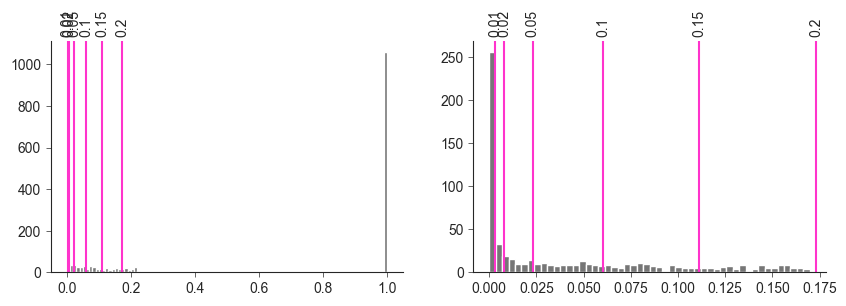

In [25]:
fig, axes = plt.subplots(1, 2, figsize=((10, 3)))
hist = axes[0].hist(snv_observations["p value"].values, bins=100, color="#767676")
hist = axes[1].hist([p for p in snv_observations["p value"].values if p < pvalue_thresholds[-1]], bins=50,  color="#767676")

for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    for i, FDR in enumerate(FDRs):
        ax.axvline(pvalue_thresholds[i], color="#FF33CC")
        ax.text(pvalue_thresholds[i],ax.get_ylim()[-1]+(ax.get_ylim()[-1]/50), str(FDR), 
                rotation=90, va="bottom", ha="center", size=10)


#### 3.3.1. Assess assignment of trajectories with different FDR 

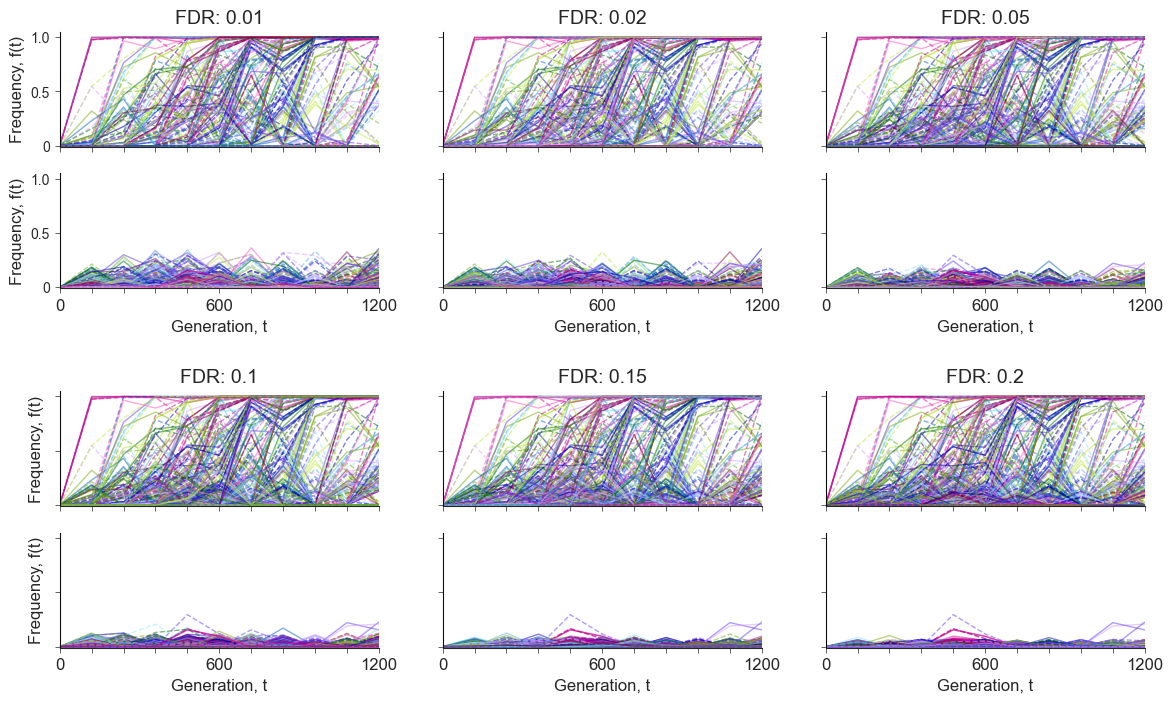

In [26]:
fig = plt.figure(figsize=(14, 8))
gs = gridspec.GridSpec(2, 3, wspace=0.2, hspace=0.4,)

dont_plot_fixed = False

for i, fdr in enumerate(FDRs):
    gs_i = i // 3 
    gs_j = i % 3 
    
    gsi = gridspec.GridSpecFromSubplotSpec(2,1, wspace=0.35, hspace=0.23, subplot_spec=gs[gs_i,gs_j], height_ratios=[1,1])
    non_drift_ax = fig.add_subplot(gsi[0])
    drift_ax = fig.add_subplot(gsi[1])
    
    drift_df = snv_observations[snv_observations["p value"]>pvalue_thresholds[i]].reset_index().set_index(["population", "refname","nucpos", "snv"])
    idx_list = drift_df.index.tolist()

    random.shuffle(idx_list)
    for (population, refname, nucpos, snv) in idx_list:
        freqs = [f for f in trajectories.loc[(population, refname, nucpos, snv)] if not pd.isna(f)]
        timepoints = passages
        donor, replicate = population
        drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=0.5, ls='-' if snv in non_synonymous_dict[refname] else '--')
        
    non_drift_df = snv_observations[snv_observations["p value"]<=pvalue_thresholds[i]].reset_index().set_index(["population", "refname","nucpos", "snv"])
    idx_list = non_drift_df.index.tolist()

    random.shuffle(idx_list)
    for (population, refname, nucpos, snv) in idx_list:
        if dont_plot_fixed:
            if "F" in  HMM_states.loc[(population, refname, nucpos, snv)].tolist():
                continue
        freqs = [f for f in trajectories.loc[(population, refname, nucpos, snv)] if not pd.isna(f)]
        timepoints = passages
        donor, replicate = population
        non_drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=0.5, ls='-' if snv in non_synonymous_dict[refname] else '--')
          
    for ax in [drift_ax, non_drift_ax]:
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
        if i !=0:
            ax.set_yticklabels([])
        else:
            ax.set_yticklabels([0, 0.5, 1.0], size=10)
        if gs_j ==0:
            ax.set_ylabel("Frequency, f(t)", size=12)
        
    non_drift_ax.set_title(f"FDR: {fdr}", y=1)
    drift_ax.set_xlabel("Generation, t", size=12)
    non_drift_ax.set_xticklabels([])
    drift_ax.set_xticklabels([0, "", "", "", "", int((50*hours_per_passage)/generation_time), 
                                "", "", "", "", int((100*hours_per_passage)/generation_time)], size=12)
     
fig.savefig("../figures/figS5_sensitivity_analysis_FDR.svg", dpi=300,bbox_inches='tight')
fig.savefig("../figures/figS5_sensitivity_analysis_FDR.png", dpi=300,bbox_inches='tight')    

**Figure S5 Sensitivity analysis of false discovery rates (FDR) for the statistical identification of non-neutral SNVs.** SNV trajectories are coloured by population.

### 3.4. Label final trajectories

Setting FDR to 0.01 > we can be strict here as we'd want strong evidence against drift 

fixation is evidence of non-drift here

In [27]:
#calculate threshold P-value 
FDR = 0.01
pvalues = snv_observations["p value"].values
pvalues = [p for p in pvalues if p < 1]
total_pvalues = len(pvalues)

for p in sorted(pvalues, reverse=True):
    if total_pvalues*p/(pvalues<=p).sum() < FDR:
        break
threshold_pvalue = p
print (f"threshold p-value with FDR of {FDR}: {threshold_pvalue}")


threshold p-value with FDR of 0.01: 0.0031996800319968


In [28]:
#label final trajectories
for i, row in snv_observations.iterrows():
    snv_observations.loc[i, "evidence for non-drift"] = False if row["p value"] > threshold_pvalue else True

In [29]:
for idx in snv_summary.index.unique():
    if "F" in  HMM_states.loc[idx].tolist():
        snv_summary.loc[idx, "status"] = "fixed"
    elif all(s =="U" for  s in HMM_states.loc[idx].tolist()):
        snv_summary.loc[idx, "status"] = "drift"
        
    elif True in snv_observations.loc[idx, "evidence for non-drift"].tolist():
        snv_summary.loc[idx, "status"] = "transient"
    else:
        snv_summary.loc[idx, "status"] = "drift"

## 4. Visualize plot trajectory classification

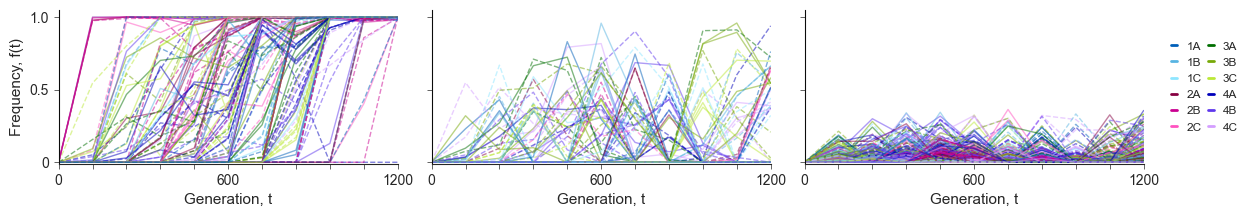

In [30]:
fig, axes = plt.subplots(1,3, figsize=((14,2)))
fig.subplots_adjust(wspace=0.1)

#fixers
fix_ax, non_drift_ax, drift_ax = axes

idx_list = snv_observations.index.tolist()
random.shuffle(idx_list)

seen_idx = []
for (population, refname, nucpos, snv, observation) in idx_list:
    if (population, refname, nucpos, snv, observation) in seen_idx:
        continue
    seen_idx.append((population, refname, nucpos, snv, observation))
       
    freqs = [f for f in trajectories.loc[(population, refname, nucpos, snv)] if not pd.isna(f)]
    timepoints = passages
    if "F" in  HMM_states.loc[(population, refname, nucpos, snv)].tolist():
        fix_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=0.5, ls='-' if snv in non_synonymous_dict[refname] else '--')
        continue
    
    if snv_observations.loc[(population, refname, nucpos, snv, observation), "evidence for non-drift"]:
        non_drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=0.5, ls='-' if snv in non_synonymous_dict[refname] else '--')
    else:
        drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=0.5, ls='-' if snv in non_synonymous_dict[refname] else '--')

#cosmetics
for ax in axes:
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, timepoints[-1])
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])

    ax.set_yticklabels([])

    ax.set_xticklabels([0, "", "", "", "", int((50*hours_per_passage)/generation_time), 
                                "", "", "", "", int((100*hours_per_passage)/generation_time)], size=10)
    
    ax.set_xlabel("Generation, t", size=11)
     
fix_ax.set_yticklabels([0, 0.5, 1.0], size=10)
fix_ax.set_ylabel("Frequency, f(t)", size=11)

leg = drift_ax.legend(handles=population_legend_elements, loc='center left',  
                        bbox_to_anchor=(1.05,0.5), ncols =2, fontsize=8.5, handlelength=0.5, edgecolor=None, frameon=False, 
                        columnspacing=0.5)
               

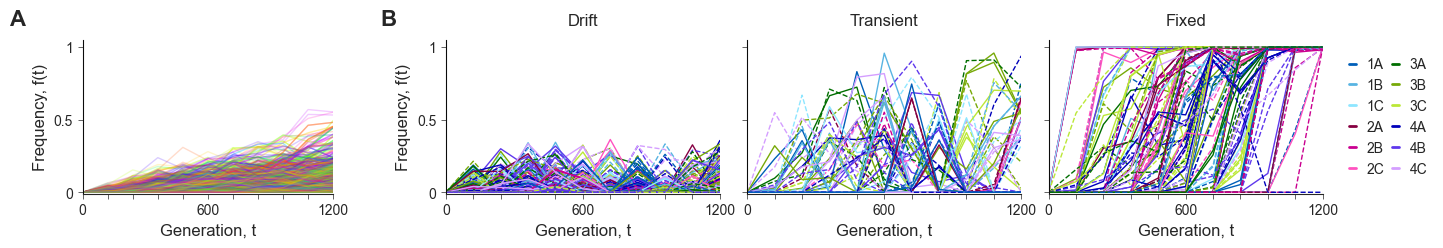

In [31]:
fig = plt.figure(figsize=(16, 2))
gs = gridspec.GridSpec(1,1, wspace=0.05, hspace=0.8)

random.seed(88)

gsi = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[0], wspace=0.2, width_ratios=[1,3.5])

#simulated trajectories
n_sims_toplot = 12
color_list = [mcolors.to_hex(cm.gist_rainbow(i /( n_sims_toplot-1))) for i in range(n_sims_toplot)]
random_sims_toplot = random.sample(simulations.index.get_level_values(1).unique().tolist(), n_sims_toplot)
unique_trajectories_only=True

sim_ax = fig.add_subplot(gsi[0])
if unique_trajectories_only:
    sims = simulations.drop_duplicates()
    indices = sims.index.tolist()
    random.shuffle(indices)  
for (ref, sim,p) in indices:
    if sim not in random_sims_toplot:
        continue
    freqs = sims.loc[(ref, sim, p)].values
    sim_ax.plot(passages, freqs, lw=1, alpha=0.2, color=color_list[random_sims_toplot.index(sim)])
sim_ax.set_ylabel("Frequency, f(t)", size=12)

#Big overview panal
gsi0 = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=gsi[-1], wspace=0.1)
drift_ax, non_drift_ax, fix_ax = fig.add_subplot(gsi0[0]),fig.add_subplot(gsi0[1]), fig.add_subplot(gsi0[2])

idx_list = snv_observations.index.tolist()
random.shuffle(idx_list)

seen_idx = []
for (population, refname, nucpos, snv, observation) in idx_list:
    if (population, refname, nucpos, snv, observation) in seen_idx:
        continue
    seen_idx.append((population, refname, nucpos, snv, observation))
       
    freqs = [f for f in trajectories.loc[(population, refname, nucpos, snv)] if not pd.isna(f)]
    timepoints = passages
    if "F" in  HMM_states.loc[(population, refname, nucpos, snv)].tolist():
        fix_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        continue
    
    if snv_observations.loc[(population, refname, nucpos, snv, observation), "evidence for non-drift"]:
        non_drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
    else:
        drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')

#cosmetics
for ax in [sim_ax, fix_ax, non_drift_ax, drift_ax]:
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, timepoints[-1])
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])

    ax.set_yticklabels([])

    ax.set_xticklabels([0, "", "", "", "", int((50*hours_per_passage)/generation_time), 
                                "", "", "", "", int((100*hours_per_passage)/generation_time)], size=10)
    
    ax.set_xlabel("Generation, t", size=12)
       
drift_ax.set_yticklabels([0, 0.5, 1], size=10)
drift_ax.set_ylabel("Frequency, f(t)", size=12)
sim_ax.set_yticklabels([0, 0.5, 1], size=10)

fix_ax.text(50, 1.15, "Fixed", ha="center", size=12)
non_drift_ax.text(50, 1.15, "Transient", ha="center", size=12)
drift_ax.text(50, 1.15, "Drift", ha="center", size=12)

#panel label
drift_ax.text(-24, 1.15, "B", size=16, fontweight="bold")
sim_ax.text(-29, 1.15, "A", size=16, fontweight="bold")


leg = fix_ax.legend(handles=population_legend_elements, loc='center left',  
                        bbox_to_anchor=(1.05,0.5), ncols =2, fontsize=10, handlelength=0.5, edgecolor=None, frameon=False, 
                        columnspacing=0.5)



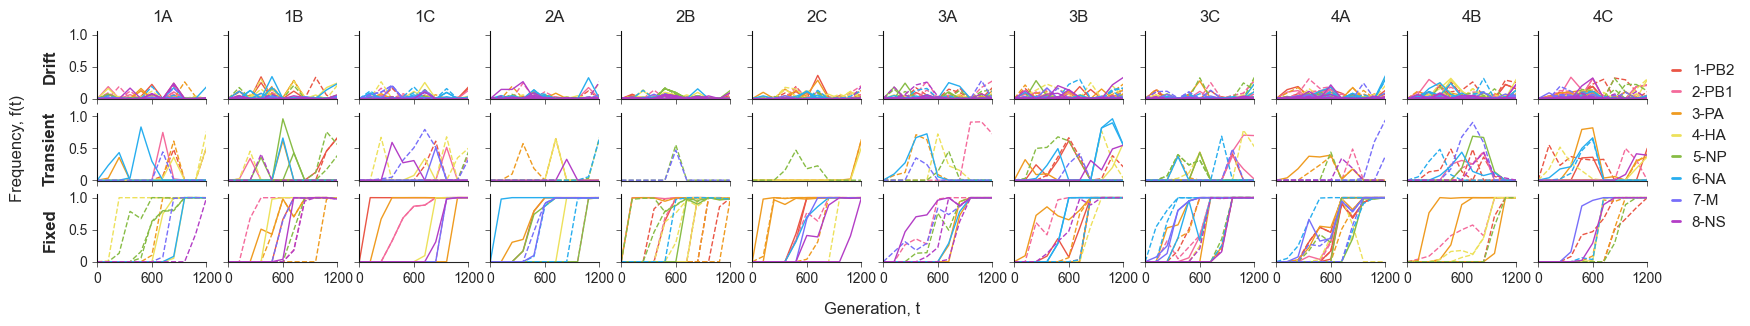

In [32]:
fig, axes = plt.subplots(3,12, figsize=((20,3)))
seen_idx = []

for i, population in enumerate(populations):
    
    drift_ax, non_drift_ax, fix_ax = axes[0,i], axes[1,i], axes[2,i]
    idx_list = snv_observations.loc[population].index.tolist()
    
    drift_ax.text(50, 1.2, population, size=12, )
    
    for (refname, nucpos, snv, observation) in idx_list:
        if (population, refname, nucpos, snv, observation) in seen_idx:
            continue
        seen_idx.append((population, refname, nucpos, snv, observation))
    
       
        freqs = [f for f in trajectories.loc[(population, refname, nucpos, snv)] if not pd.isna(f)]
        timepoints = passages
        if "F" in  HMM_states.loc[(population, refname, nucpos, snv)].tolist():
            fix_ax.plot(timepoints, freqs, c=segment_cpal[segments.index(refname)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
            continue
       
        if snv_observations.loc[(population, refname, nucpos, snv, observation), "evidence for non-drift"]:
            non_drift_ax.plot(timepoints, freqs, c=segment_cpal[segments.index(refname)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        else:
            drift_ax.plot(timepoints, freqs, c=segment_cpal[segments.index(refname)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
 
#cosmetics
for i, row in enumerate(axes):
    for j, ax in enumerate(row):
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_xticks([0,  50,  100])

        ax.set_yticklabels([])

        ax.set_xticklabels([])
        
        if i == 2:
            #ax.set_xlabel("Generation, t", size=10)
            ax.set_xticklabels([0, int((50*hours_per_passage)/generation_time),  int((100*hours_per_passage)/generation_time)], size=10)
        
        if j == 0:
            ax.set_yticklabels([0, 0.5, 1.0], size=10)
            #ax.set_ylabel("Frequency, f(t)", size=10)
            
axes[1,0].text(-80, 0.5, "Frequency, f(t)", size=12, rotation=90, va="center")
axes[2,5].text(110, -0.8, "Generation, t", size=12, ha="center")

axes[2,0].text(-50, 0.5, "Fixed", size=12, rotation=90, va="center", fontweight="bold")
axes[1,0].text(-50, 0.5, "Transient", size=12, rotation=90, va="center", fontweight="bold")
axes[0,0].text(-50, 0.5, "Drift", size=12, rotation=90, va="center", fontweight="bold")

segment_legend_elements = []
for i , s in enumerate(segments):
    segment_legend_elements.append(Line2D([0], [0], color=segment_cpal[i], label=s, linewidth=2,  ))

leg = axes[1,-1].legend(handles=segment_legend_elements, loc='center left', bbox_to_anchor=(1.1,0.5), ncols =1, fontsize=11, handlelength=0.5,
                            edgecolor=None, frameon=False, columnspacing=0.5)
    

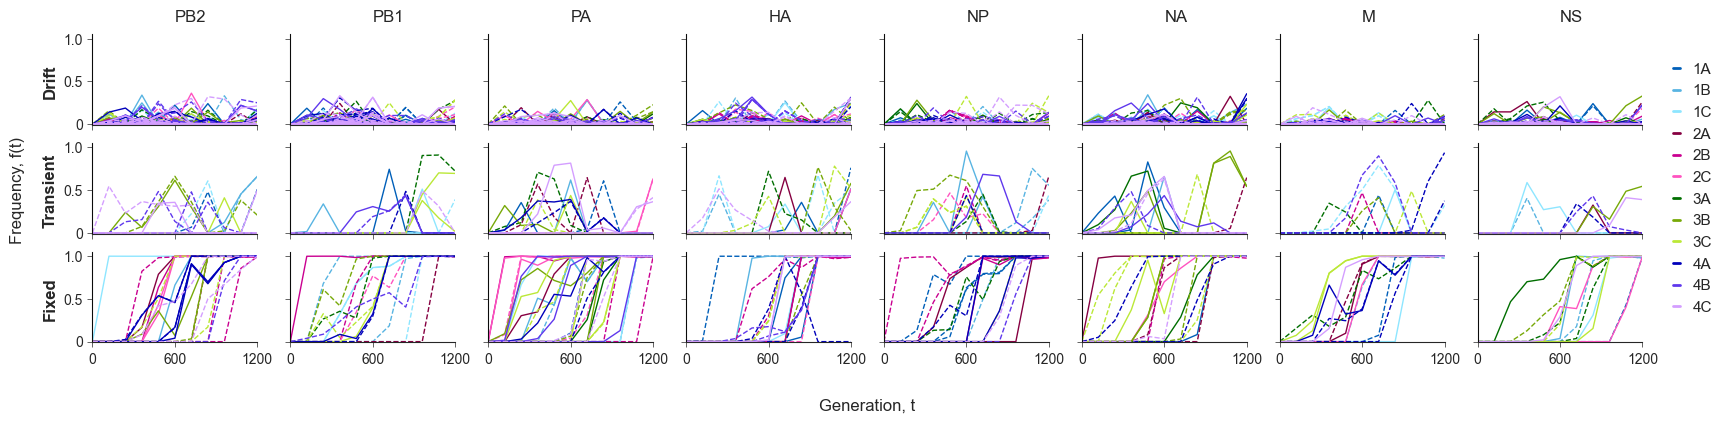

In [33]:
fig, axes = plt.subplots(3,8, figsize=((20,4 )))

seen_idx = []
for i, refname in enumerate(segments):
    drift_ax, non_drift_ax, fix_ax = axes[0,i], axes[1,i], axes[2,i]
    idx_list = snv_observations.reset_index().set_index(["refname", "population", "nucpos", "snv", "observation"]
                                                        ).sort_index().loc[refname].index.tolist()
    

    drift_ax.text(50, 1.2, refname.split("-")[-1], size=12, )
    
    for (population, nucpos, snv, observation) in idx_list:
        if (population, refname, nucpos, snv, observation) in seen_idx:
            continue
        seen_idx.append((population, refname, nucpos, snv, observation))
    
       
        freqs = [f for f in trajectories.loc[(population, refname, nucpos, snv)] if not pd.isna(f)]
        timepoints = passages
        if "F" in  HMM_states.loc[(population, refname, nucpos, snv)].tolist():
            fix_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
            continue
       
        if snv_observations.loc[(population, refname, nucpos, snv, observation), "evidence for non-drift"]:
            non_drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        else:
            drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')

#cosmetics
for i, row in enumerate(axes):
    for j, ax in enumerate(row):
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_xticks([0,  50,  100])

        ax.set_yticklabels([])

        ax.set_xticklabels([])
        
        if i == 2:
            #ax.set_xlabel("Generation, t", size=10)
            ax.set_xticklabels([0, int((50*hours_per_passage)/generation_time),  int((100*hours_per_passage)/generation_time)], size=10)
        
        if j == 0:
            ax.set_yticklabels([0, 0.5, 1.0], size=10)
            #ax.set_ylabel("Frequency, f(t)", size=10)
            
axes[1,0].text(-50, 0.5, "Frequency, f(t)", size=12, rotation=90, va="center")
axes[2,3].text(110, -0.8, "Generation, t", size=12, ha="center")

axes[2,0].text(-30, 0.5, "Fixed", size=12, rotation=90, va="center", fontweight="bold")
axes[1,0].text(-30, 0.5, "Transient", size=12, rotation=90, va="center", fontweight="bold")
axes[0,0].text(-30, 0.5, "Drift", size=12, rotation=90, va="center", fontweight="bold")


leg = axes[1,-1].legend(handles=population_legend_elements, loc='center left', bbox_to_anchor=(1.1,0.5), ncols =1, fontsize=11, handlelength=0.5,
                            edgecolor=None, frameon=False, columnspacing=0.5)
    


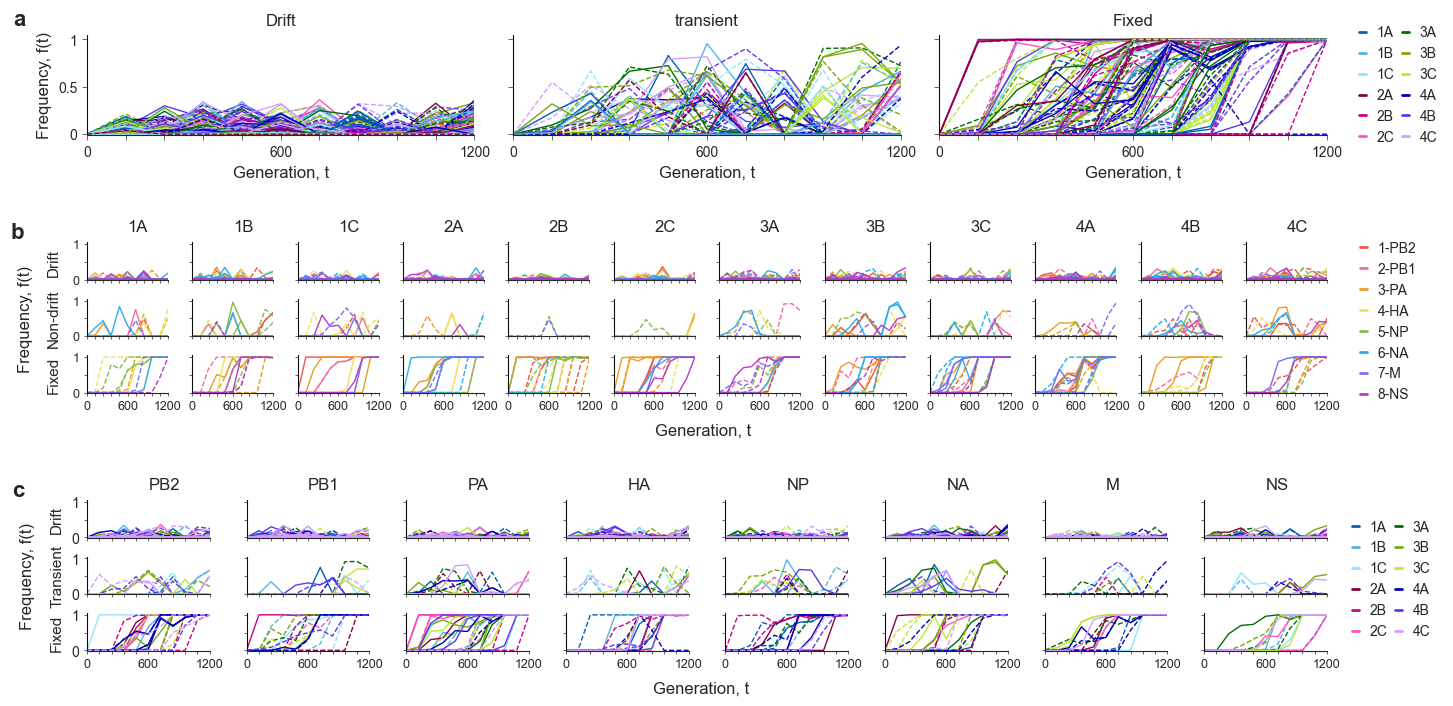

In [34]:
fig = plt.figure(figsize=(16, 8))
gs = gridspec.GridSpec(3,1, height_ratios=[1,1.5, 1.5], wspace=0.05, hspace=0.8)

#Big overview panal
gsi = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=gs[0], wspace=0.1)
drift_ax, non_drift_ax, fix_ax = fig.add_subplot(gsi[0]),fig.add_subplot(gsi[1]), fig.add_subplot(gsi[2])

idx_list = snv_observations.index.tolist()
random.shuffle(idx_list)

seen_idx = []
for (population, refname, nucpos, snv, observation) in idx_list:
    if (population, refname, nucpos, snv, observation) in seen_idx:
        continue
    seen_idx.append((population, refname, nucpos, snv, observation))
       
    freqs = [f for f in trajectories.loc[(population, refname, nucpos, snv)] if not pd.isna(f)]
    timepoints = passages
    if "F" in  HMM_states.loc[(population, refname, nucpos, snv)].tolist():
        fix_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        continue
    
    if snv_observations.loc[(population, refname, nucpos, snv, observation), "evidence for non-drift"]:
        non_drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
    else:
        drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')

#cosmetics
for ax in [fix_ax, non_drift_ax, drift_ax]:
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, timepoints[-1])
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
    

    ax.set_yticklabels([])

    ax.set_xticklabels([0, "", "", "", "", int((50*hours_per_passage)/generation_time), 
                                "", "", "", "", int((100*hours_per_passage)/generation_time)], size=10)
    
    ax.set_xlabel("Generation, t", size=12)
       
drift_ax.set_yticklabels([0, 0.5, 1], size=10)
drift_ax.set_ylabel("Frequency, f(t)", size=12)

fix_ax.text(50, 1.15, "Fixed", ha="center", size=12)
non_drift_ax.text(50, 1.15, "transient", ha="center", size=12)
drift_ax.text(50, 1.15, "Drift", ha="center", size=12)

#panel label
drift_ax.text(-19, 1.15, "a", size=16, fontweight="bold")

leg = fix_ax.legend(handles=population_legend_elements, loc='center left',  
                        bbox_to_anchor=(1.05,0.5), ncols =2, fontsize=10, handlelength=0.5, edgecolor=None, frameon=False, 
                        columnspacing=0.5)

#population summary figure
gsi = gridspec.GridSpecFromSubplotSpec(3, 12, subplot_spec=gs[1], hspace=0.5, wspace=0.3)

seen_idx = []
for i, population in enumerate(populations):
    
    drift_ax, non_drift_ax, fix_ax = fig.add_subplot(gsi[0,i]),fig.add_subplot(gsi[1,i]), fig.add_subplot(gsi[2,i])
    idx_list = snv_observations.loc[population].index.tolist()
    
    drift_ax.text(50, 1.35, population, size=12, )
    
    for (refname, nucpos, snv, observation) in idx_list:
        if (population, refname, nucpos, snv, observation) in seen_idx:
            continue
        seen_idx.append((population, refname, nucpos, snv, observation))
    
       
        freqs = [f for f in trajectories.loc[(population, refname, nucpos, snv)] if not pd.isna(f)]
        timepoints = passages
        if "F" in  HMM_states.loc[(population, refname, nucpos, snv)].tolist():
            fix_ax.plot(timepoints, freqs, c=segment_cpal[segments.index(refname)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
            continue
       
        if snv_observations.loc[(population, refname, nucpos, snv, observation), "evidence for non-drift"]:
            non_drift_ax.plot(timepoints, freqs, c=segment_cpal[segments.index(refname)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        else:
            drift_ax.plot(timepoints, freqs, c=segment_cpal[segments.index(refname)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
 
    for j, ax in enumerate([fix_ax, non_drift_ax, drift_ax]):
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_xticks([0,  50,  100])
        ax.set_xticks(passages)
        
        ax.set_yticklabels([])
        ax.set_xticklabels([])
        ax.tick_params(length=2)
        
        
       
        if j == 0:  
            #ax.set_xticklabels([0, int((50*hours_per_passage)/generation_time),  int((100*hours_per_passage)/generation_time)], size=9)
            ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=9)
            
        
        if i == 0:
            ax.set_yticklabels([0, '', 1], size=9)
            #ax.set_ylabel("Frequency, f(t)", size=10)
    
    if i ==0:   
        non_drift_ax.text(-85, 0.5, "Frequency, f(t)", size=12, rotation=90, va="center")
        fix_ax.text(-50, 0.5, "Fixed", size=11, rotation=90, va="center", )
        non_drift_ax.text(-50, 0.5, "Non-drift", size=11, rotation=90, va="center", )
        drift_ax.text(-50, 0.5, "Drift", size=11, rotation=90, va="center", )
        #panel label
        drift_ax.text(-95, 1.15, "b", size=16, fontweight="bold")
        
    
    if population == populations[-1]: 
        leg =non_drift_ax.legend(handles=segment_legend_elements, loc='center left', bbox_to_anchor=(1.25,0.4), ncols =1, fontsize=10, handlelength=0.5,
                            edgecolor=None, frameon=False, columnspacing=0.5)
        
    if i == 5:
        fix_ax.text(110, -1.2, "Generation, t", size=12, ha="center")
    
#segment summary figure
gsi = gridspec.GridSpecFromSubplotSpec(3, 8, subplot_spec=gs[2], hspace=0.5, wspace=0.3)
seen_idx = []
for i, refname in enumerate(segments):
    #fix_ax, non_drift_ax, drift_ax = axes[0,i], axes[1,i], axes[2,i]
    drift_ax, non_drift_ax, fix_ax = fig.add_subplot(gsi[0,i]),fig.add_subplot(gsi[1,i]), fig.add_subplot(gsi[2,i])
    
    idx_list = snv_observations.reset_index().set_index(["refname", "population", "nucpos", "snv", "observation"]
                                                        ).sort_index().loc[refname].index.tolist()
    

    drift_ax.text(50, 1.35, refname.split("-")[-1], size=12, )
    
    for (population, nucpos, snv, observation) in idx_list:
        if (population, refname, nucpos, snv, observation) in seen_idx:
            continue
        seen_idx.append((population, refname, nucpos, snv, observation))
    
       
        freqs = [f for f in trajectories.loc[(population, refname, nucpos, snv)] if not pd.isna(f)]
        timepoints = passages
        if "F" in  HMM_states.loc[(population, refname, nucpos, snv)].tolist():
            fix_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
            continue
       
        if snv_observations.loc[(population, refname, nucpos, snv, observation), "evidence for non-drift"]:
            non_drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        else:
            drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')

    for j, ax in enumerate([fix_ax, non_drift_ax, drift_ax]):
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_xticks([0,  50,  100])
        ax.set_xticks(passages)

        ax.set_yticklabels([])

        ax.set_xticklabels([])
        ax.tick_params(length=2)
        
        if j == 0:
            #ax.set_xlabel("Generation, t", size=10)
            #ax.set_xticklabels([0, int((50*hours_per_passage)/generation_time),  int((100*hours_per_passage)/generation_time)], size=10)
            ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=9)

        if i == 0:
            ax.set_yticklabels([0, '', 1], size=10)
            
    if i ==0:   
        non_drift_ax.text(-55, 0.5, "Frequency, f(t)", size=12, rotation=90, va="center")
        fix_ax.text(-30, 0.5, "Fixed", size=11, rotation=90, va="center", )
        non_drift_ax.text(-30, 0.5, "Transient", size=11, rotation=90, va="center", )
        drift_ax.text(-30, 0.5, "Drift", size=11, rotation=90, va="center", )
        drift_ax.text(-61, 1.15, "c", size=16, fontweight="bold")
    
    
    if refname == segments[-1]: 
        leg =non_drift_ax.legend(handles=population_legend_elements, loc='center left', bbox_to_anchor=(1.1,0.4), ncols =2, fontsize=10, handlelength=0.5,
                            edgecolor=None, frameon=False, columnspacing=0.5)
        
    if i == 3:
        fix_ax.text(110, -1.2, "Generation, t", size=12, ha="center")


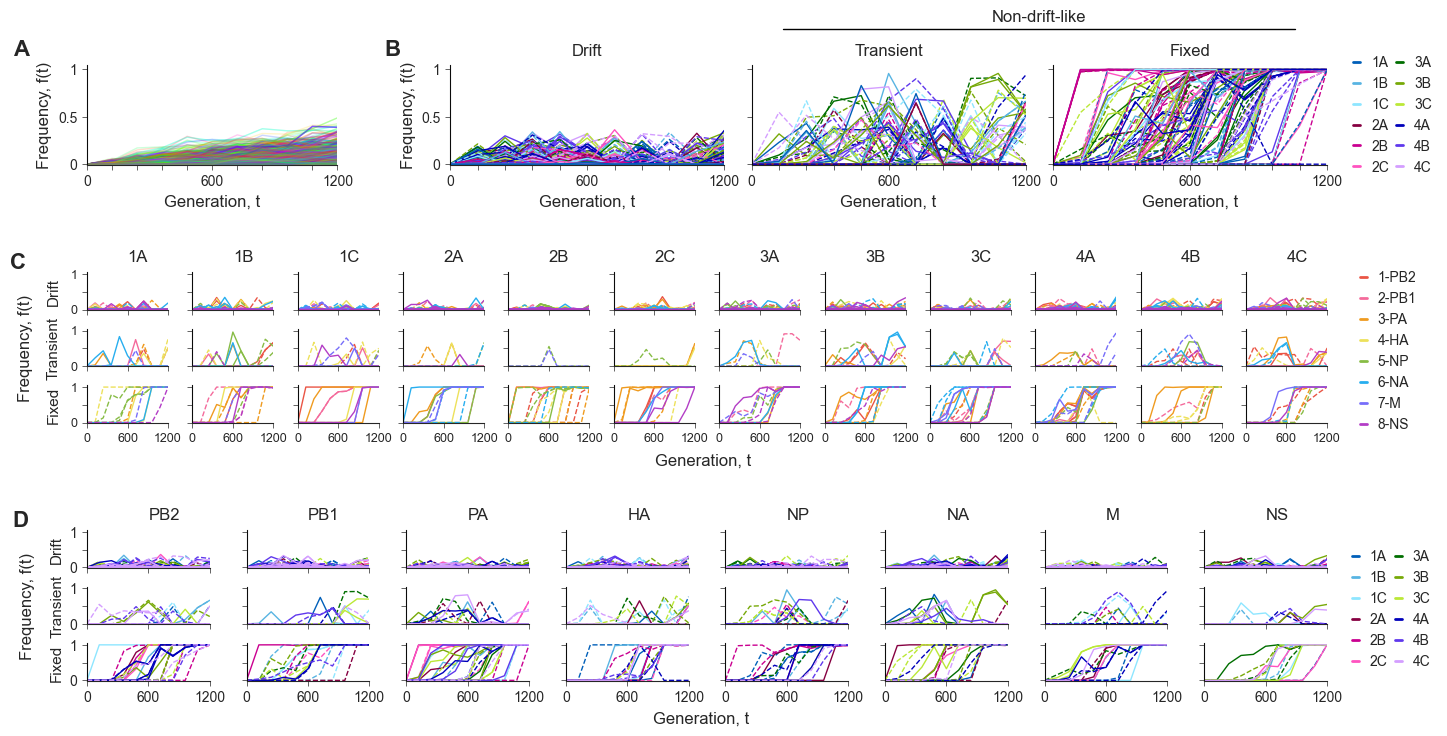

In [35]:

fig = plt.figure(figsize=(16, 8))
gs = gridspec.GridSpec(3,1, height_ratios=[1,1.5, 1.5], wspace=0.05, hspace=0.8)

random.seed(92382455771)

gsi = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[0], wspace=0.2, width_ratios=[1,3.5])

#simulated trajectories
n_sims_toplot = 12
color_list = [mcolors.to_hex(cm.gist_rainbow(i /( n_sims_toplot-1))) for i in range(n_sims_toplot)]
random_sims_toplot = random.sample(simulations.index.get_level_values(1).unique().tolist(), n_sims_toplot)
unique_trajectories_only=True

sim_ax = fig.add_subplot(gsi[0])
if unique_trajectories_only:
    sims = simulations.drop_duplicates()
    indices = sims.index.tolist()
    random.shuffle(indices)  
for (ref, sim,p) in indices:
    if sim not in random_sims_toplot:
        continue
    freqs = sims.loc[(ref, sim, p)].values
    sim_ax.plot(passages, freqs, lw=1, alpha=0.2, color=color_list[random_sims_toplot.index(sim)])
sim_ax.set_ylabel("Frequency, f(t)", size=12)

#Big overview panal
gsi0 = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=gsi[-1], wspace=0.1)
drift_ax, non_drift_ax, fix_ax = fig.add_subplot(gsi0[0]),fig.add_subplot(gsi0[1]), fig.add_subplot(gsi0[2])

idx_list = snv_observations.index.tolist()
random.shuffle(idx_list)

seen_idx = []
for (population, refname, nucpos, snv, observation) in idx_list:
    if (population, refname, nucpos, snv, observation) in seen_idx:
        continue
    seen_idx.append((population, refname, nucpos, snv, observation))
       
    freqs = [f for f in trajectories.loc[(population, refname, nucpos, snv)] if not pd.isna(f)]
    timepoints = passages
    if "F" in  HMM_states.loc[(population, refname, nucpos, snv)].tolist():
        fix_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        continue
    
    if snv_observations.loc[(population, refname, nucpos, snv, observation), "evidence for non-drift"]:
        non_drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
    else:
        drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')

#cosmetics
for ax in [sim_ax, fix_ax, non_drift_ax, drift_ax]:
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, timepoints[-1])
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])

    ax.set_yticklabels([])

    ax.set_xticklabels([0, "", "", "", "", int((50*hours_per_passage)/generation_time), 
                                "", "", "", "", int((100*hours_per_passage)/generation_time)], size=10)
    
    ax.set_xlabel("Generation, t", size=12)
       
drift_ax.set_yticklabels([0, 0.5, 1], size=10)
drift_ax.set_ylabel("Frequency, f(t)", size=12)
sim_ax.set_yticklabels([0, 0.5, 1], size=10)

fix_ax.text(50, 1.15, "Fixed", ha="center", size=12)
non_drift_ax.text(50, 1.15, "Transient", ha="center", size=12)
drift_ax.text(50, 1.15, "Drift", ha="center", size=12)

#panel label
drift_ax.text(-24, 1.15, "B", size=16, fontweight="bold")
sim_ax.text(-29, 1.15, "A", size=16, fontweight="bold")


leg = fix_ax.legend(handles=population_legend_elements, loc='center left',  
                        bbox_to_anchor=(1.05,0.5), ncols =2, fontsize=10, handlelength=0.5, edgecolor=None, frameon=False, 
                        columnspacing=0.5)

#population summary figure
gsi = gridspec.GridSpecFromSubplotSpec(3, 12, subplot_spec=gs[1], hspace=0.5, wspace=0.3)

seen_idx = []
for i, population in enumerate(populations):
    
    drift_ax, non_drift_ax, fix_ax = fig.add_subplot(gsi[0,i]),fig.add_subplot(gsi[1,i]), fig.add_subplot(gsi[2,i])
    idx_list = snv_observations.loc[population].index.tolist()
    
    drift_ax.text(50, 1.35, population, size=12, )
    
    for (refname, nucpos, snv, observation) in idx_list:
        if (population, refname, nucpos, snv, observation) in seen_idx:
            continue
        seen_idx.append((population, refname, nucpos, snv, observation))
    
       
        freqs = [f for f in trajectories.loc[(population, refname, nucpos, snv)] if not pd.isna(f)]
        timepoints = passages
        if "F" in  HMM_states.loc[(population, refname, nucpos, snv)].tolist():
            fix_ax.plot(timepoints, freqs, c=segment_cpal[segments.index(refname)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
            continue
       
        if snv_observations.loc[(population, refname, nucpos, snv, observation), "evidence for non-drift"]:
            non_drift_ax.plot(timepoints, freqs, c=segment_cpal[segments.index(refname)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        else:
            drift_ax.plot(timepoints, freqs, c=segment_cpal[segments.index(refname)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
 
    for j, ax in enumerate([fix_ax, non_drift_ax, drift_ax]):
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_xticks([0,  50,  100])
        ax.set_yticklabels([])
        ax.set_xticklabels([])
        
       
        if j == 0:  
            ax.set_xticklabels([0, int((50*hours_per_passage)/generation_time),  int((100*hours_per_passage)/generation_time)], size=9)
        
        if i == 0:
            ax.set_yticklabels([0, '', 1], size=9)
            #ax.set_ylabel("Frequency, f(t)", size=10)
    
    if i ==0:   
        non_drift_ax.text(-85, 0.5, "Frequency, f(t)", size=12, rotation=90, va="center")
        fix_ax.text(-50, 0.5, "Fixed", size=11, rotation=90, va="center", )
        non_drift_ax.text(-50, 0.5, "Transient", size=11, rotation=90, va="center", )
        drift_ax.text(-50, 0.5, "Drift", size=11, rotation=90, va="center", )
        #panel label
        drift_ax.text(-95, 1.15, "C", size=16, fontweight="bold")
        
    
    if population == populations[-1]: 
        leg =non_drift_ax.legend(handles=segment_legend_elements, loc='center left', bbox_to_anchor=(1.25,0.4), ncols =1, fontsize=10, handlelength=0.5,
                            edgecolor=None, frameon=False, columnspacing=0.5)
        
    if i == 5:
        fix_ax.text(110, -1.2, "Generation, t", size=12, ha="center")
    
#segment summary figure
gsi = gridspec.GridSpecFromSubplotSpec(3, 8, subplot_spec=gs[2], hspace=0.5, wspace=0.3)
seen_idx = []
for i, refname in enumerate(segments):
    #fix_ax, non_drift_ax, drift_ax = axes[0,i], axes[1,i], axes[2,i]
    drift_ax, non_drift_ax, fix_ax = fig.add_subplot(gsi[0,i]),fig.add_subplot(gsi[1,i]), fig.add_subplot(gsi[2,i])
    
    idx_list = snv_observations.reset_index().set_index(["refname", "population", "nucpos", "snv", "observation"]
                                                        ).sort_index().loc[refname].index.tolist()
    

    drift_ax.text(50, 1.35, refname.split("-")[-1], size=12, )
    
    for (population, nucpos, snv, observation) in idx_list:
        if (population, refname, nucpos, snv, observation) in seen_idx:
            continue
        seen_idx.append((population, refname, nucpos, snv, observation))
    
       
        freqs = [f for f in trajectories.loc[(population, refname, nucpos, snv)] if not pd.isna(f)]
        timepoints = passages
        if "F" in  HMM_states.loc[(population, refname, nucpos, snv)].tolist():
            fix_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
            continue
       
        if snv_observations.loc[(population, refname, nucpos, snv, observation), "evidence for non-drift"]:
            non_drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        else:
            drift_ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1., alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')

    for j, ax in enumerate([fix_ax, non_drift_ax, drift_ax]):
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_xticks([0,  50,  100])

        ax.set_yticklabels([])

        ax.set_xticklabels([])
        
        if j == 0:
            #ax.set_xlabel("Generation, t", size=10)
            ax.set_xticklabels([0, int((50*hours_per_passage)/generation_time),  int((100*hours_per_passage)/generation_time)], size=10)
        
        if i == 0:
            ax.set_yticklabels([0, '', 1], size=10)
            
    if i ==0:   
        non_drift_ax.text(-55, 0.5, "Frequency, f(t)", size=12, rotation=90, va="center")
        fix_ax.text(-30, 0.5, "Fixed", size=11, rotation=90, va="center", )
        non_drift_ax.text(-30, 0.5, "Transient", size=11, rotation=90, va="center", )
        drift_ax.text(-30, 0.5, "Drift", size=11, rotation=90, va="center", )
        drift_ax.text(-61, 1.15, "D", size=16, fontweight="bold")
        
    
    if refname == segments[-1]: 
        leg =non_drift_ax.legend(handles=population_legend_elements, loc='center left', bbox_to_anchor=(1.1,0.4), ncols =2, fontsize=10, handlelength=0.5,
                            edgecolor=None, frameon=False, columnspacing=0.5)
        
    if i == 3:
        fix_ax.text(110, -1.2, "Generation, t", size=12, ha="center")

fig.text(0.72, 0.93, "Non-drift-like", size=12, ha="center", va="bottom")
line = Line2D([0.56, 0.88], [0.925, 0.925], transform=fig.transFigure, color='black', linewidth=1)
fig.add_artist(line)
fig.savefig("../figures/fig3_trajectory_classification.svg", dpi=300,bbox_inches='tight')
fig.savefig("../figures/fig3_trajectory_classification.png", dpi=300,bbox_inches='tight')   

**Figure 3 Frequency trajectories of observed SNVs classified based on the statistical inference of drift-like behaviour compared to simulated drift-like trajectories.** A, simulated drift(-like) trajectories. B, Observed SNV frequency trajectories by SNV classification. From left to right: trajectories of SNVs with drift-like behaviour, SNVs with significant non-drift-like behaviour, and fixed SNVs. SNV trajectories are coloured per population. C, SNV trajectories per population per SNV classification coloured by segment. D, SNV trajectories per segment per SNV classification coloured by population. Solid and dotted lines indicate non-synonymous and synonymous SNVs, respectively.

## 5. Obtain final dataframe

In [36]:
snv_summary.to_csv("../results/snv_summary_annotated.csv")